In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import pandas as pd
import zarr
import numpy as np

from dotenv import dotenv_values
from scipy.stats import entropy

In [3]:
# Load config file agnostic to project or notebook work directory
config_path = Path("config.env")
if not config_path.exists():
    config_path = Path("../../../config.env")
CONFIG = dotenv_values(config_path)
assert CONFIG != {}, 'Configuration is empty - check the filepath.'

# Main data directory
DATADIR = Path(CONFIG['DATADIR'])

# Submodule specific data directory
OUTDIR = DATADIR / '10_analyses' / 'region_heterogeneity'
OUTDIR.mkdir(parents=True, exist_ok=True)

In [11]:
# Load region-wise relative mass table
df_region_relmass = pd.read_csv(DATADIR / '9_objects/spatial/regionwise_relative_masses/regionwise_relative_masses.csv', index_col='celltype_id')
df_region_relmass.drop(columns=['celltype_descr', 'celltype_abc_like', 'flag'], inplace=True)

### Approach 1: count top region assignment only
Only assign a cell-type as belonging to a region if it is the top relative mass.

In [18]:
region_counts = np.zeros(df_region_relmass.shape[1])
top_indices = np.argmax(df_region_relmass, axis=1)
np.add.at(region_counts, top_indices, 1)

<Axes: >

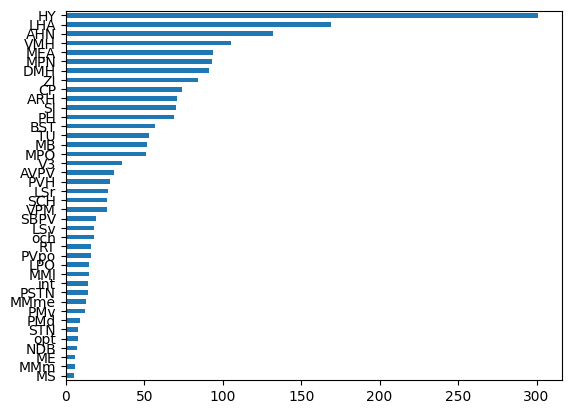

In [24]:
pd.Series(region_counts, index=df_region_relmass.columns).sort_values(ascending=True).tail(40).plot.barh()

### Approach 2: arbitary threshold
Only assign a cell-type as belonging to a region if its relative mass exceeds a threshold.

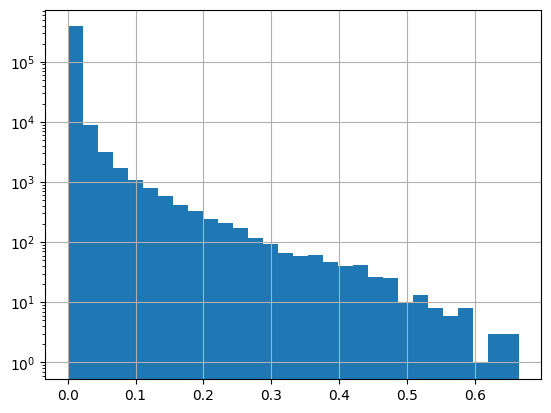

In [30]:
region_counts = pd.Series(df_region_relmass.values.ravel()).hist(bins=30, log=True)

<Axes: >

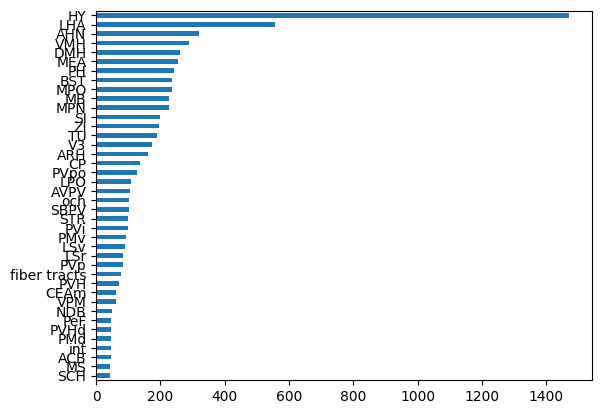

In [31]:
region_counts = np.sum((df_region_relmass.values > 0.05).astype(np.int32), axis=0)
pd.Series(region_counts, index=df_region_relmass.columns).sort_values(ascending=True).tail(40).plot.barh()

### Approach 3: top 5 values per cell-type

Only assign a cell-type as belonging to a region if it is the top 5 of its relative mass.

In [32]:
k = 5 # top 5
region_counts = np.zeros(df_region_relmass.shape[1])
top_indices = np.argpartition(df_region_relmass.values, -k, axis=1)[:, -k:]
np.add.at(region_counts, top_indices, 1)

<Axes: >

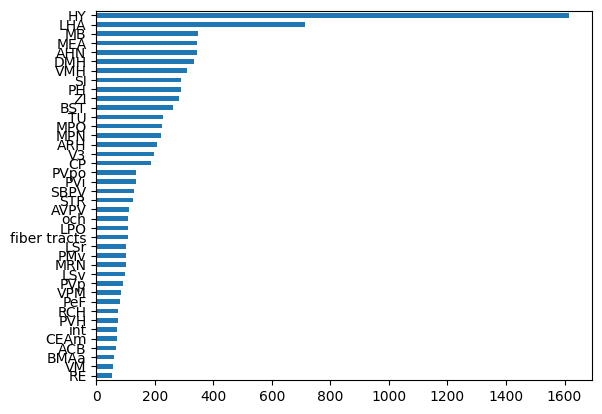

In [33]:
pd.Series(region_counts, index=df_region_relmass.columns).sort_values(ascending=True).tail(40).plot.barh()